# Taswira Analytics: Finding Standard Fetal Planes in Novice Blind Sweeps
### Group 11 Capstone · final notebook

**Problem.** Midwives with little ultrasound training can acquire *blind sweeps* (free-hand passes of a handheld probe, about 200 frames each), but cannot judge whether a sweep contains a diagnostic frame. We build a lightweight model that finds the five ISUOG standard planes (head, abdomen, heart, spine, femur) in every frame and decides whether the sweep should be repeated.

**Data**

| Dataset | Content | Role |
|---|---|---|
| [NatalIA PBF-US1](https://zenodo.org/records/14193949) | 90 blind sweeps (19,407 frames) of a 23-week **phantom** by 45 novices; 98% of frames show no plane | Training and testing |
| [FETAL_PLANES_DB](https://zenodo.org/record/3904280) | ~12,400 real hospital images, Barcelona | Extra training images (never tested on) |
| [African fetal planes](https://zenodo.org/records/7540448) | 450 real images, Malawi, Uganda, Egypt, Ghana, Algeria | External test only |

**Research questions.** RQ1 plane recognition · RQ2 sweep-level frame finding and rescan decision · RQ3 robustness to sweep type · RQ4 size and speed on a phone · RQ5 effect of real images, and performance on real African scans · RQ6 can a sweep flag a possible breech (feasibility)?

**Showcase.** Section 8 adds an exploratory brain-defect screening step with safe, non-diagnostic messages; section 9 runs a full midwife visit: danger-sign check, scan quality, best frames, breech flag, guidance card and referral note, with an interactive version.

**Method in one line.** Frozen ImageNet features (EfficientNet-B0 + MobileNetV2) → logistic regression with hard-negative mining → thresholds tuned on held-out sweeps → 5-fold cross-validation grouped by sweep.

> **Settings** are fixed to the best configuration from our exploratory runs (v3.1–v3.2: 18 configurations, nested CV, ablations). **To run:** keep the three downloads (`NatalIA PBFUS1.zip`, `FETAL_PLANES_ZENODO.zip`, `Zenodo_dataset.tar.xz`) or their extracted folders next to this notebook and choose *Run All*. Preprocessing and features are cached in `cache/`.

## 0. Setup

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import re, json, random, pathlib, warnings, time, zipfile, tarfile, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from IPython.display import display
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, f1_score, recall_score,
                             roc_auc_score, average_precision_score)
warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")
sns.set_theme(style="whitegrid")
print("TensorFlow", tf.__version__)

TensorFlow 2.22.0-rc0


In [2]:
SEED = 42
NOTEBOOK_DIR = pathlib.Path.cwd()
CACHE_DIR, OUT_DIR = NOTEBOOK_DIR / "cache", NOTEBOOK_DIR / "outputs"
CACHE_DIR.mkdir(exist_ok=True); OUT_DIR.mkdir(exist_ok=True)

CLASS_NAMES = ["biparietal", "abdominal", "heart", "spine", "femur", "no_plane"]
NO_PLANE, PLANE_IDS = 5, [0, 1, 2, 3, 4]
EXT_TARGETS = ["biparietal", "abdominal", "heart", "femur"]       # views shared with the real-image datasets
EXT_IDS = [CLASS_NAMES.index(c) for c in EXT_TARGETS]

# Preprocessing
IMG_SIZE, CROP_THRESHOLD, CONTRAST_PCT = 224, 2.0, (1, 99.5)
BUFFER = 3                     # no-plane frames within ±3 of a plane are ambiguous: never used as negatives

# Model (best configuration from exploratory runs)
FEATURE_BACKBONES = ["efficientnetb0", "mobilenetv2"]   # features concatenated
EMB_BATCH = 64
LR_C = 0.03                    # logistic-regression regularisation
NO_PLANE_RATIO = 10            # random no-plane frames per plane frame
HARD_NEG_RATIO = 5             # hard negatives added per plane frame
SPAIN_PER_VIEW = 400           # real Spanish images per class added in the "+ Spain" model

# Evaluation
N_FOLDS, INNER_VAL_FRAC = 5, 0.25
FRAME_TAUS = np.round(np.arange(0.05, 0.96, 0.05), 2)
SWEEP_TARGET_SENS = 0.90       # share of plane-containing sweeps that must pass
N_BOOT = 1000
COUNTRIES = ["algeria", "egypt", "ghana", "malawi", "uganda"]

np.random.seed(SEED); tf.random.set_seed(SEED); random.seed(SEED)

## 1. Data

### 1.1 Locate and unpack the three datasets

In [3]:
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def search(pattern):
    return sorted(p for p in NOTEBOOK_DIR.rglob(pattern) if not {"cache", "outputs"} & set(p.parts))

def ensure(meta_name, archives, target):
    # Return the metadata file, unpacking the archive next to the notebook if needed.
    hits = search(meta_name)
    if not hits:
        for a in archives:
            print(f"Extracting {a.name} ...")
            target.mkdir(exist_ok=True)
            (zipfile.ZipFile(a) if a.suffix == ".zip" else tarfile.open(a)).extractall(target)
        hits = search(meta_name)
    return hits[0] if hits else None

NATALIA_META = ensure("resume.csv", [z for z in NOTEBOOK_DIR.glob("*.zip") if "natalia" in z.name.lower()],
                      NOTEBOOK_DIR / "NatalIA PBFUS1")
SPAIN_META = ensure("FETAL_PLANES_DB_data.csv", [z for z in NOTEBOOK_DIR.glob("*.zip") if "fetal_planes" in z.name.lower()],
                    NOTEBOOK_DIR / "FETAL_PLANES_DB")
AFRICA_META = ensure("African_planes_database.csv", list(NOTEBOOK_DIR.glob("*.tar.xz")), NOTEBOOK_DIR / "African_planes")
assert NATALIA_META, "Put 'NatalIA PBFUS1.zip' or its folder next to this notebook."
print("NatalIA:", NATALIA_META.parent, "\nSpain:  ", SPAIN_META, "\nAfrica: ", AFRICA_META)

NatalIA: C:\Users\pc\PycharmProjects\TaswiraAi_analytics\NatalIA PBFUS1 
Spain:   None 
Africa:  None


### 1.2 NatalIA frames and sweep metadata

One row per frame (`resume.csv`), joined to sweep type and fetal position (`metadata.csv`). Frames are put in sweep order from their file names. Volunteer demographics are not used.

In [4]:
DATA_DIR = NATALIA_META.parent
frames = pd.read_csv(DATA_DIR / "resume.csv")
frames.columns = [c.strip() for c in frames.columns]
frames["path"] = [str(DATA_DIR / s / f) for s, f in zip(frames["studie"], frames["file_name"])]
frames = frames[frames["path"].map(os.path.exists)]
frames["label"], frames["video"] = frames["value"].astype(int), frames["studie"].astype(str)

studies = pd.read_csv(DATA_DIR / "metadata.csv")
studies.columns = [c.strip() for c in studies.columns]
norm = lambda s: re.sub(r"\s+", " ", str(s)).strip().lower()
meta = (studies.assign(video_key=studies["Study Name"].map(norm))[["video_key", "protocol", "position"]]
        .rename(columns={"protocol": "sweep_type", "position": "fetal_position"}).drop_duplicates("video_key"))
frames = frames.assign(video_key=frames["video"].map(norm)).merge(meta, on="video_key", how="left")
frames["sweep_type"] = (frames["sweep_type"].fillna("unknown").str.strip().str.lower()
                        .replace({"diagonal": "diagonal 1", "diagonal /": "diagonal 2"}))
frames["fetal_position"] = frames["fetal_position"].fillna("unknown").str.strip().str.upper()
frames["frame_no"] = pd.to_numeric(frames["file_name"].str.extract(r"cineframe_(\d+)", expand=False), errors="coerce")
frames = frames.sort_values(["video", "frame_no", "file_name"]).reset_index(drop=True)
frames["pos"] = frames.groupby("video").cumcount()

per_video = frames.groupby("video").agg(n_frames=("label", "size"), sweep_type=("sweep_type", "first"),
                                        plane_frames=("label", lambda s: (s != NO_PLANE).sum()))
counts = frames["label"].value_counts().reindex(range(6), fill_value=0)
display(pd.DataFrame({"frames": counts.values, "share %": (100 * counts / counts.sum()).round(2).values},
                     index=CLASS_NAMES))
print(f"{len(per_video)} sweeps, median {per_video['n_frames'].median():.0f} frames; "
      f"{(per_video['plane_frames'] == 0).sum()} sweeps contain no standard plane.")

,frames,share %
biparietal,42,0.22
abdominal,63,0.32
heart,61,0.31
spine,134,0.69
femur,46,0.24
no_plane,19061,98.22


90 sweeps, median 210 frames; 36 sweeps contain no standard plane.


### 1.3 Preprocessing (cached)

All frames come from one probe and depth, so the ultrasound sector is found once from the mean of 300 frames. Each frame is cropped to it, contrast-stretched (1st–99.5th percentile), padded to a square and resized to 224×224. Frames are cached as a memory-mapped array.

In [5]:
rng0 = np.random.default_rng(SEED)
sample_paths = rng0.choice(frames["path"].values, size=min(300, len(frames)), replace=False)
mean_img = np.mean([np.asarray(Image.open(p).convert("L"), dtype=np.float32) for p in sample_paths], axis=0)
rows, cols = np.where((mean_img > CROP_THRESHOLD).any(1))[0], np.where((mean_img > CROP_THRESHOLD).any(0))[0]
CROP = (int(max(cols[0] - 4, 0)), int(max(rows[0] - 4, 0)),
        int(min(cols[-1] + 5, mean_img.shape[1])), int(min(rows[-1] + 5, mean_img.shape[0])))

def stretch_pad(a):
    lo, hi = np.percentile(a, CONTRAST_PCT)
    a = np.clip((a - lo) / max(hi - lo, 1e-6) * 255.0, 0, 255).astype(np.uint8)
    h, w = a.shape; s = max(h, w)
    sq = np.zeros((s, s), np.uint8)
    sq[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = a
    return np.asarray(Image.fromarray(sq).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))

def preprocess(img_gray):                      # NatalIA: fixed sector crop
    return stretch_pad(np.asarray(img_gray.crop(CROP), dtype=np.float32))

def preprocess_external(img_gray):             # other datasets: crop box found per image
    a = np.asarray(img_gray, dtype=np.float32)
    m = a > 8
    r, c = np.where(m.mean(1) > 0.02)[0], np.where(m.mean(0) > 0.02)[0]
    if len(r) > 10 and len(c) > 10:
        a = a[r[0]:r[-1] + 1, c[0]:c[-1] + 1]
    return stretch_pad(a)

cfg_key = f"{IMG_SIZE}_{CROP}_{CONTRAST_PCT}"
img_path, stats_path, key_path = CACHE_DIR / "frames.npy", CACHE_DIR / "frame_stats.csv", CACHE_DIR / "frames_key.json"
if not (img_path.exists() and stats_path.exists() and key_path.exists()
        and json.loads(key_path.read_text()) == {"key": cfg_key, "n": len(frames)}):
    t0 = time.time()
    store = np.lib.format.open_memmap(img_path, mode="w+", dtype=np.uint8, shape=(len(frames), IMG_SIZE, IMG_SIZE))
    stats = []
    for i, p in enumerate(frames["path"]):
        g = Image.open(p).convert("L")
        a = np.asarray(g, dtype=np.float32)
        d = np.asarray(g.resize((17, 16)), dtype=np.int16)
        stats.append({"brightness": a.mean(), "contrast": a.std(),
                      "dhash": np.packbits((d[:, 1:] > d[:, :-1]).ravel()).tobytes().hex()})
        store[i] = preprocess(g)
    store.flush(); del store
    pd.DataFrame(stats).to_csv(stats_path, index=False)
    key_path.write_text(json.dumps({"key": cfg_key, "n": len(frames)}))
    print(f"Preprocessed {len(frames)} frames in {time.time() - t0:.0f}s")
IMAGES = np.load(img_path, mmap_mode="r")
frames = pd.concat([frames, pd.read_csv(stats_path)], axis=1)
frames["row"] = np.arange(len(frames))
print("Crop box:", CROP)

Crop box: (50, 28, 657, 467)


### 1.4 Label clean-up

Exact duplicate frames with conflicting labels are removed. No-plane frames within ±3 frames of a plane are flagged as *ambiguous*: they look almost identical to the plane frame, so they are never used as training negatives (they are still tested on).

In [6]:
conflict = frames.groupby("dhash")["label"].transform("nunique") > 1
frames = frames[~conflict].reset_index(drop=True)
frames["pos"] = frames.groupby("video").cumcount()
near = np.zeros(len(frames), bool)
for vid, idx in frames.groupby("video").indices.items():
    g = frames.iloc[idx]
    pp = g.loc[g["label"] != NO_PLANE, "pos"].values
    if len(pp):
        near[idx] = (np.abs(g["pos"].values[:, None] - pp[None, :]).min(1) <= BUFFER) & (g["label"].values == NO_PLANE)
frames["near_plane"] = near
Y = frames["label"].values
print(f"Removed {conflict.sum()} conflicting duplicates; {near.sum()} ambiguous no-plane frames; "
      f"{(Y != NO_PLANE).sum()} plane frames in {len(frames)}.")

Removed 2 conflicting duplicates; 1422 ambiguous no-plane frames; 345 plane frames in 19405.


### 1.5 Real-image datasets: label mapping

| NatalIA class | Spain (FETAL_PLANES_DB) | Africa |
|---|---|---|
| biparietal | Fetal brain, trans-thalamic only | brain |
| abdominal | Fetal abdomen | abdomen |
| heart | Fetal thorax | thorax |
| femur | Fetal femur | femur |
| no plane | Other, maternal cervix | — |

Spine has no counterpart. Other brain planes are left out (neither the target view nor clearly "no plane").

In [7]:
def resolve_index(root):
    idx = {}
    for p in root.rglob("*"):
        if p.suffix.lower() in IMG_EXT:
            idx.setdefault(p.name.lower(), p); idx.setdefault(p.stem.lower(), p)
    return idx

def map_view(plane, brain=""):
    p, b = str(plane).lower(), str(brain).lower()
    if "abdom" in p: return "abdominal"
    if "femur" in p: return "femur"
    if "thorax" in p: return "heart"
    if "brain" in p: return "biparietal" if (not b or "thalamic" in b) else None
    if "cervix" in p or p.strip() == "other": return "no_plane"
    return None

spain = pd.DataFrame()
if SPAIN_META:
    m = pd.read_csv(SPAIN_META, sep=None, engine="python"); m.columns = [c.strip() for c in m.columns]
    ix = resolve_index(SPAIN_META.parent)
    spain = pd.DataFrame({"path": [str(ix.get(str(n).lower(), "")) or None for n in m["Image_name"]],
                          "cls": [map_view(p, b) for p, b in zip(m["Plane"], m["Brain_plane"])],
                          "patient": m["Patient_num"].astype(str)}).dropna(subset=["path", "cls"]).reset_index(drop=True)
    order = spain.sample(frac=1, random_state=SEED).groupby("cls", group_keys=False)
    spain_used = spain.loc[order.apply(lambda g: g.head(SPAIN_PER_VIEW)).index.values].reset_index(drop=True)
    print(f"Spain: {len(spain)} usable images; {len(spain_used)} used for training "
          f"({SPAIN_PER_VIEW} per class):", spain_used["cls"].value_counts().to_dict())

africa = pd.DataFrame()
if AFRICA_META:
    m = pd.read_csv(AFRICA_META, sep=None, engine="python"); m.columns = [c.strip() for c in m.columns]
    ix = resolve_index(AFRICA_META.parent)
    paths = [str(ix.get(str(n).lower(), ix.get(pathlib.Path(str(n)).stem.lower(), ""))) or None for n in m["Filename"]]
    africa = pd.DataFrame({"path": paths, "cls": [map_view(p) for p in m["Plane"]],
                           "country": m["Center"].astype(str).str.lower(),
                           "patient": m["Center"].astype(str) + ":" + m["Patient_num"].astype(str)})
    africa = africa.dropna(subset=["path", "cls"]).reset_index(drop=True)
    display(pd.crosstab(africa["country"], africa["cls"], margins=True))
Y_SPAIN = spain_used["cls"].map(CLASS_NAMES.index).values if len(spain) else np.array([], int)
Y_AFRICA = africa["cls"].map(CLASS_NAMES.index).values if len(africa) else np.array([], int)

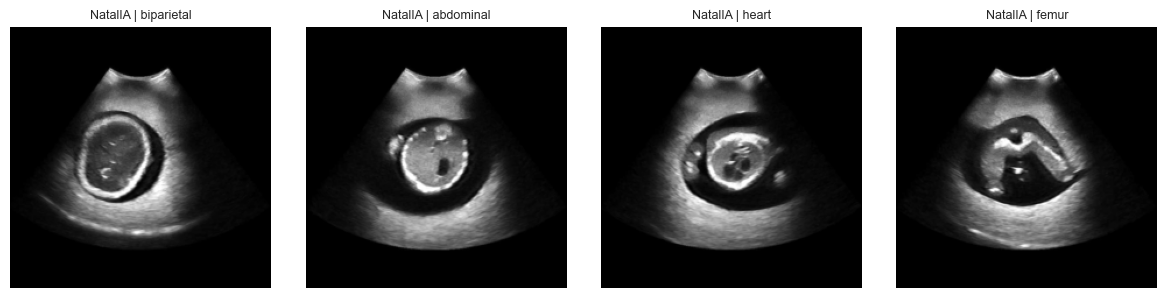

In [8]:
# Visual check of the mapping: each column should show the same view
src = [("NatalIA", None)] + [(n, d) for n, d in [("Spain", spain), ("Africa", africa)] if len(d)]
fig, axes = plt.subplots(len(src), 4, figsize=(12, 3 * len(src)), squeeze=False)
for r, (name, d) in enumerate(src):
    for c, cls in enumerate(EXT_TARGETS):
        ax = axes[r, c]; ax.axis("off"); ax.set_title(f"{name} | {cls}", fontsize=9)
        if d is None:
            ax.imshow(IMAGES[frames.loc[frames["label"] == CLASS_NAMES.index(cls), "row"].iloc[0]], cmap="gray")
        elif (d["cls"] == cls).any():
            ax.imshow(preprocess_external(Image.open(d.loc[d["cls"] == cls, "path"].iloc[0]).convert("L")), cmap="gray")
plt.tight_layout(); plt.show()

## 2. Features (computed once, cached)

Each image passes once through EfficientNet-B0 and MobileNetV2 (ImageNet weights, global average pooling); the two 1,280-d vectors are concatenated. Backbone weights are saved so the packaged model in section 6 reproduces the cached features exactly.

In [9]:
def make_backbone(name):
    inp = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    if name == "efficientnetb0":
        base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", pooling="avg",
                                                 input_shape=(IMG_SIZE, IMG_SIZE, 3)); x = inp
    else:
        base = keras.applications.MobileNetV2(include_top=False, weights="imagenet", pooling="avg",
                                              input_shape=(IMG_SIZE, IMG_SIZE, 3)); x = layers.Rescaling(1 / 127.5, offset=-1)(inp)
    return keras.Model(inp, base(x, training=False), name=f"{name}_features")

def get_backbone(name):
    path = CACHE_DIR / f"backbone_{name}_{IMG_SIZE}.weights.h5"
    model = make_backbone(name)
    model.load_weights(path) if path.exists() else model.save_weights(path)
    return model

def embed(name, load_batch, n, path):
    if path.exists() and (CACHE_DIR / f"backbone_{name}_{IMG_SIZE}.weights.h5").exists():
        F = np.load(path)
        if len(F) == n:
            return F.astype(np.float32)
    model, F, t0 = get_backbone(name), None, time.time()
    for s in range(0, n, EMB_BATCH):
        out = model.predict(np.repeat(load_batch(s, min(s + EMB_BATCH, n))[..., None], 3, -1).astype(np.float32), verbose=0)
        F = np.zeros((n, out.shape[1]), np.float32) if F is None else F
        F[s:s + len(out)] = out
    np.save(path, F.astype(np.float16)); keras.backend.clear_session()
    print(f"{path.name}: {F.shape} in {time.time() - t0:.0f}s")
    return F

def features(df_paths=None, tag=None):
    out = {}
    for b in FEATURE_BACKBONES:
        if df_paths is None:          # NatalIA frames from the cache
            path = CACHE_DIR / f"feat_{b}_{hashlib.md5(cfg_key.encode()).hexdigest()[:8]}.npy"
            out[b] = embed(b, lambda s, e: np.asarray(IMAGES[s:e]), len(IMAGES), path)
        else:
            key = hashlib.md5((tag + cfg_key + "|".join(df_paths)).encode()).hexdigest()[:10]
            path = CACHE_DIR / f"ext_{tag}_{b}_{key}.npy"
            out[b] = embed(b, lambda s, e: np.stack([preprocess_external(Image.open(p).convert("L"))
                                                      for p in df_paths[s:e]]), len(df_paths), path)
    return np.hstack([out[b] for b in FEATURE_BACKBONES])

X = features()[frames["row"].values]
X_SPAIN = features(list(spain_used["path"]), "spain") if len(spain) else np.zeros((0, X.shape[1]))
X_AFRICA = features(list(africa["path"]), "africa") if len(africa) else np.zeros((0, X.shape[1]))
print("Features:", X.shape, X_SPAIN.shape, X_AFRICA.shape)

Features: (19405, 2560) (0, 2560) (0, 2560)


## 3. Model and evaluation design

**Training set (per fit).** Every plane frame + 10 random non-ambiguous no-plane frames per plane frame. A first logistic regression then scores the remaining no-plane frames, and the 5 × (plane frames) most plane-like are added (**hard-negative mining**) before refitting. In the "+ Spain" model, the Spanish images are added to every fit (never to testing).

**Decisions.** Frame: *plane* if P(plane) = 1 − P(no plane) ≥ τ, type = most likely plane. Sweep: score = best frame's P(plane); sweeps below τ_sweep are flagged for rescan.

**Evaluation.** 5 outer folds grouped by sweep. Inside each, an inner split of the training sweeps tunes τ (max plane macro-F1) and τ_sweep (≥ 90% of plane-containing sweeps pass). Test folds are never used for tuning.

In [10]:
def fit_logreg(Xt, yt):
    scaler = StandardScaler().fit(Xt)
    present = np.unique(yt)
    cw = dict(zip(present, compute_class_weight("balanced", classes=present, y=yt)))
    clf = LogisticRegression(C=LR_C, max_iter=3000, class_weight=cw).fit(scaler.transform(Xt), yt)
    return scaler, clf

def predict(model, Xq):
    scaler, clf = model
    P = np.zeros((len(Xq), 6)); P[:, clf.classes_] = clf.predict_proba(scaler.transform(Xq))
    return P

def train(idx, rng, use_spain):
    sub = frames.iloc[idx]
    pos = idx[sub["label"].values != NO_PLANE]
    pool = idx[(sub["label"].values == NO_PLANE) & ~sub["near_plane"].values]
    tr = np.concatenate([pos, rng.choice(pool, min(len(pool), NO_PLANE_RATIO * len(pos)), replace=False)])
    extra = (X_SPAIN, Y_SPAIN) if use_spain else (X[:0], Y[:0])
    fit = lambda r: fit_logreg(np.vstack([X[r], extra[0]]), np.concatenate([Y[r], extra[1]]))
    model = fit(tr)
    rest = np.setdiff1d(pool, tr)                                   # hard-negative mining
    if not len(rest):
        return model
    hard = rest[np.argsort(-(1 - predict(model, X[rest])[:, NO_PLANE]))[:HARD_NEG_RATIO * len(pos)]]
    return fit(np.concatenate([tr, hard]))

def decide(P, tau):
    return np.where(1 - P[:, NO_PLANE] >= tau, np.array(PLANE_IDS)[P[:, PLANE_IDS].argmax(1)], NO_PLANE)

def plane_f1(y, pred):
    labels = sorted((set(np.unique(y)) | set(np.unique(pred))) - {NO_PLANE})
    return f1_score(y, pred, labels=labels, average="macro", zero_division=0) if labels else np.nan

def sweep_scores(P, idx):
    df = pd.DataFrame({"video": frames["video"].values[idx], "p": 1 - P[:, NO_PLANE],
                       "has_plane": Y[idx] != NO_PLANE})
    return df.groupby("video").agg(score=("p", "max"), has_plane=("has_plane", "any"))

def tune(P, idx):
    tau = max(FRAME_TAUS, key=lambda t: plane_f1(Y[idx], decide(P, t)))
    pos = np.sort(sweep_scores(P, idx).query("has_plane")["score"].values)
    tau_sweep = float(pos[int(np.floor((1 - SWEEP_TARGET_SENS) * len(pos)))]) - 1e-9 if len(pos) else 0.5
    return {"tau": float(tau), "tau_sweep": tau_sweep}

def grouped_folds(df, k, seed=SEED):
    fold = np.full(len(df), -1)
    sgkf = StratifiedGroupKFold(n_splits=min(k, df["video"].nunique()), shuffle=True, random_state=seed)
    for i, (_, te) in enumerate(sgkf.split(df, df["label"], df["video"])):
        fold[te] = i
    return fold

frames["fold"] = grouped_folds(frames, N_FOLDS)
assert frames.groupby("video")["fold"].nunique().max() == 1
display(pd.crosstab(frames["label"].map(dict(enumerate(CLASS_NAMES))), frames["fold"]).reindex(CLASS_NAMES))

fold,0,1,2,3,4
label,,,,,
biparietal,9,7,10,7,9
abdominal,9,11,19,11,13
heart,11,11,16,12,11
spine,18,24,47,21,23
femur,11,8,9,11,7
no_plane,3823,3817,3793,3827,3800


In [11]:
def cross_validate(use_spain):
    P_oof, pred, params = np.zeros((len(frames), 6)), np.full(len(frames), NO_PLANE), {}
    for f in range(N_FOLDS):
        te, tr = np.where(frames["fold"].values == f)[0], np.where(frames["fold"].values != f)[0]
        rng = np.random.default_rng(SEED + f)
        inner = grouped_folds(frames.iloc[tr], int(round(1 / INNER_VAL_FRAC)), SEED + f)
        in_tr, in_val = tr[inner != 0], tr[inner == 0]
        params[f] = tune(predict(train(in_tr, rng, use_spain), X[in_val]), in_val)
        P_oof[te] = predict(train(tr, rng, use_spain), X[te])
        pred[te] = decide(P_oof[te], params[f]["tau"])
    return {"P": P_oof, "pred": pred, "params": params}

MODELS = {"Dummy only": False}
if len(spain):
    MODELS[f"Dummy + Spain ({SPAIN_PER_VIEW}/class)"] = True
t0 = time.time()
CV = {name: cross_validate(flag) for name, flag in MODELS.items()}
print(f"Cross-validation done in {time.time() - t0:.0f}s")

Cross-validation done in 155s


## 4. Results on the phantom sweeps (RQ1–RQ3, RQ5a)

All numbers are out-of-fold. 95% intervals come from 1,000 bootstrap resamples of **sweeps**. Plain accuracy is not reported as a headline: predicting "no plane" everywhere already scores 98%.

### 4.1 Frame and sweep metrics

In [12]:
VIDEO_IDX = list(frames.groupby("video").indices.values())
def boot_ci(stat):
    rng = np.random.default_rng(SEED)
    vals = [stat(np.concatenate([VIDEO_IDX[i] for i in rng.integers(0, len(VIDEO_IDX), len(VIDEO_IDX))]))
            for _ in range(N_BOOT)]
    return np.nanpercentile(vals, [2.5, 97.5])

def hit_at(P, k=5):
    hits = [(Y[ix][np.argsort(-P[ix, c])][:k] == c).any()
            for ix in VIDEO_IDX for c in PLANE_IDS if (Y[ix] == c).any()]
    return np.mean(hits)

ROWS, SWEEPS = [], {}
for name, r in CV.items():
    P, pred = r["P"], r["pred"]
    sw = pd.concat([sweep_scores(P[frames["fold"].values == f], np.where(frames["fold"].values == f)[0])
                    .assign(tau=p["tau_sweep"]) for f, p in r["params"].items()])
    sw["flagged"] = sw["score"] < sw["tau"]
    SWEEPS[name] = sw
    lo, hi = boot_ci(lambda i: plane_f1(Y[i], pred[i]))
    folds = [plane_f1(Y[frames["fold"].values == f], pred[frames["fold"].values == f]) for f in range(N_FOLDS)]
    ROWS.append({"model": name, "plane macro-F1": plane_f1(Y, pred), "95% CI": f"{lo:.3f}–{hi:.3f}",
                 "per-fold F1": " ".join(f"{v:.2f}" for v in folds),
                 "plane-present AUC": roc_auc_score(Y != NO_PLANE, 1 - P[:, NO_PLANE]),
                 "plane-present AP": average_precision_score(Y != NO_PLANE, 1 - P[:, NO_PLANE]),
                 "sweep hit@5": hit_at(P),
                 "sweep sensitivity": (~sw.loc[sw["has_plane"], "flagged"]).mean(),
                 "sweep specificity": sw.loc[~sw["has_plane"], "flagged"].mean()})
RESULTS = pd.DataFrame(ROWS)
display(RESULTS.round(3))
print(f"Chance level for AP: {(Y != NO_PLANE).mean():.3f}")

,model,plane macro-F1,95% CI,per-fold F1,plane-present AUC,plane-present AP,sweep hit@5,sweep sensitivity,sweep specificity
0,Dummy only,0.379,0.303–0.434,0.28 0.51 0.44 0.28 0.44,0.915,0.339,0.76,0.852,0.306


Chance level for AP: 0.018


### 4.2 Per-view results and confusion matrix

,Dummy only
F1 per view,
biparietal,0.536
abdominal,0.438
heart,0.566
spine,0.272
femur,0.084



Dummy only:
              precision    recall  f1-score   support

  biparietal      0.429     0.714     0.536        42
   abdominal      0.361     0.556     0.438        63
       heart      0.438     0.803     0.566        61
       spine      0.208     0.391     0.272       133
       femur      0.062     0.130     0.084        46
    no_plane      0.991     0.976     0.983     19060

    accuracy                          0.968     19405
   macro avg      0.415     0.595     0.480     19405
weighted avg      0.978     0.968     0.972     19405



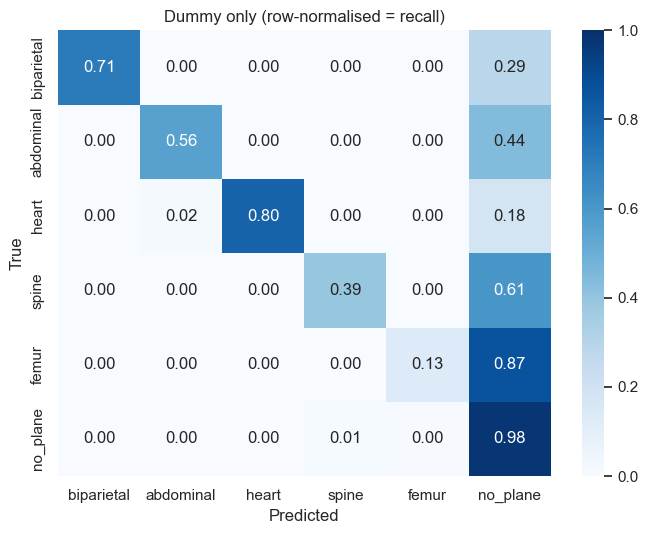

In [13]:
display(pd.DataFrame({name: f1_score(Y, r["pred"], labels=PLANE_IDS, average=None, zero_division=0)
                      for name, r in CV.items()}, index=CLASS_NAMES[:5]).round(3).rename_axis("F1 per view"))
base = list(CV)[0]
print(f"\n{base}:\n" + classification_report(Y, CV[base]["pred"], labels=range(6), target_names=CLASS_NAMES,
                                              digits=3, zero_division=0))
fig, axes = plt.subplots(1, len(CV), figsize=(7 * len(CV), 5.5), squeeze=False)
for ax, (name, r) in zip(axes[0], CV.items()):
    cm = confusion_matrix(Y, r["pred"], labels=range(6))
    sns.heatmap(cm / cm.sum(1, keepdims=True).clip(min=1), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
                ax=ax, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(f"{name} (row-normalised = recall)"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.show()

### 4.3 Robustness to sweep type (RQ3)

In [14]:
rob = []
for st, sub in frames.groupby("sweep_type"):
    ix = sub.index.values
    pred = CV[base]["pred"]
    s = SWEEPS[base].loc[sub["video"].unique()]
    rob.append({"sweep type": st, "sweeps": len(s), "plane frames": int((Y[ix] != NO_PLANE).sum()),
                "plane recall": recall_score(Y[ix] != NO_PLANE, pred[ix] != NO_PLANE, zero_division=0),
                "plane macro-F1": plane_f1(Y[ix], pred[ix]),
                "sweep sensitivity": (~s.loc[s["has_plane"], "flagged"]).mean()})
display(pd.DataFrame(rob).set_index("sweep type").round(3))

,sweeps,plane frames,plane recall,plane macro-F1,sweep sensitivity
sweep type,,,,,
diagonal 1,20,15,0.533,0.147,0.500
diagonal 2,22,45,0.422,0.345,0.778
horizontal,27,135,0.304,0.245,0.944
vertical,21,150,0.700,0.329,0.947


## 5. Real African scans (RQ5b)

Both models are retrained on **all** phantom sweeps and applied to the 450 African images (never used for training). Every image shows one of four shared views, so we report whether it is **detected** as a key view (P(plane) ≥ τ, median τ from section 3) and whether the **right view** is named (argmax over the four views). Intervals: bootstrap over patients.

In [15]:
if len(africa):
    PAT_IDX = list(africa.groupby("patient").indices.values())
    view_f1 = lambda y, v: f1_score(y, v, labels=sorted(set(y)), average="macro", zero_division=0)
    AFR, AFR_ROWS = {}, []
    for name, flag in MODELS.items():
        model = train(np.arange(len(frames)), np.random.default_rng(SEED), flag)
        P = predict(model, X_AFRICA)
        tau = float(np.median([p["tau"] for p in CV[name]["params"].values()]))
        view = np.array(EXT_IDS)[P[:, EXT_IDS].argmax(1)]
        AFR[name] = {"model": model, "detected": (1 - P[:, NO_PLANE]) >= tau, "view": view}
        rng = np.random.default_rng(SEED)
        ci = np.nanpercentile([view_f1(Y_AFRICA[i], view[i]) for i in
                               (np.concatenate([PAT_IDX[j] for j in rng.integers(0, len(PAT_IDX), len(PAT_IDX))])
                                for _ in range(N_BOOT))], [2.5, 97.5])
        AFR_ROWS.append({"model": name, "detected as key view": AFR[name]["detected"].mean(),
                         "right view (accuracy)": (view == Y_AFRICA).mean(),
                         "right view (macro-F1)": view_f1(Y_AFRICA, view), "95% CI": f"{ci[0]:.3f}–{ci[1]:.3f}"})
    AFRICA_RESULTS = pd.DataFrame(AFR_ROWS)
    display(AFRICA_RESULTS.round(3))
    display(pd.DataFrame({name: pd.Series(r["view"] == Y_AFRICA).groupby(africa["country"]).mean()
                          for name, r in AFR.items()}).round(3).rename_axis("right view, by country"))
    fig, axes = plt.subplots(1, len(AFR), figsize=(6.5 * len(AFR), 5), squeeze=False)
    for ax, (name, r) in zip(axes[0], AFR.items()):
        cm = confusion_matrix(Y_AFRICA, r["view"], labels=EXT_IDS)
        sns.heatmap(cm / cm.sum(1, keepdims=True).clip(min=1), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
                    ax=ax, xticklabels=EXT_TARGETS, yticklabels=EXT_TARGETS)
        ax.set_title(f"African scans: {name}"); ax.set_xlabel("Predicted view"); ax.set_ylabel("True view")
    plt.tight_layout(); plt.show()

## 6. Deployment (RQ4)

The model recommended for real scans (**Dummy + Spain**, or Dummy only if the Spanish data is missing) is packaged as one Keras model: both backbones → feature standardisation → logistic regression as a softmax layer. It is exported to TensorFlow Lite and timed on CPU.

In [16]:
DEPLOY_NAME = list(MODELS)[-1]
scaler, clf = AFR[DEPLOY_NAME]["model"] if len(africa) else train(np.arange(len(frames)), np.random.default_rng(SEED), MODELS[DEPLOY_NAME])
inp = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="frame")
z = layers.Concatenate()([get_backbone(b)(inp) for b in FEATURE_BACKBONES])
z = layers.Normalization(mean=scaler.mean_, variance=scaler.var_)(z)
dense = layers.Dense(6, activation="softmax", name="plane_probs")
DEPLOY = keras.Model(inp, dense(z), name="taswira_plane_finder")
W, bias = np.zeros((z.shape[-1], 6), np.float32), np.full(6, -1e4, np.float32)
W[:, clf.classes_], bias[clf.classes_] = clf.coef_.T, clf.intercept_
dense.set_weights([W, bias])

chk = np.arange(0, len(frames), len(frames) // 64)[:64]
x_chk = np.repeat(np.asarray(IMAGES[frames["row"].values[chk]])[..., None], 3, -1).astype(np.float32)
p_pkg = DEPLOY.predict(x_chk, verbose=0)
print(f"Packaged vs pipeline: argmax agreement {(p_pkg.argmax(1) == predict((scaler, clf), X[chk]).argmax(1)).mean():.3f}")

conv = tf.lite.TFLiteConverter.from_keras_model(DEPLOY)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
tfl = conv.convert()
(OUT_DIR / "taswira_plane_finder.tflite").write_bytes(tfl)
interp = tf.lite.Interpreter(model_content=tfl); interp.allocate_tensors()
i_d, o_d = interp.get_input_details()[0], interp.get_output_details()[0]
def run(x):
    interp.set_tensor(i_d["index"], x[None]); interp.invoke(); return interp.get_tensor(o_d["index"])[0]
for _ in range(5): run(x_chk[0])
t0 = time.perf_counter()
for i in range(50): run(x_chk[i % len(x_chk)])
MS = (time.perf_counter() - t0) / 50 * 1000
DEPLOY_SUMMARY = {"TFLite MB": len(tfl) / 1e6, "CPU ms per frame": MS,
                  "TFLite vs Keras agreement": np.mean([run(x).argmax() == p.argmax() for x, p in zip(x_chk, p_pkg)])}
display(pd.DataFrame([DEPLOY_SUMMARY]).round(3))

Packaged vs pipeline: argmax agreement 1.000
Saved artifact at 'C:\Users\pc\AppData\Local\Temp\tmpsaiobjb3'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='frame')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  2504696793760: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  2504696794960: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  2504696030432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2504696031632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2504696030912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2504696031392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2504696030672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2504696033792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2504696034272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2504696032112: Tenso

,TFLite MB,CPU ms per frame,TFLite vs Keras agreement
0,7.207,339.153,1.0


## 7. Breech flag: head-down or bottom-first? (feasibility)

A baby lying bottom-first (breech) near term is a standard reason to refer. NatalIA records the baby's position for every sweep: **OA/OP = head first**, **SA/SP = bottom first (breech)**. Each sweep is summarised by the average of its frames' cached features, and a strongly regularised logistic regression predicts breech. It is tested with the **same 5 folds**, so every sweep is predicted by a model that never saw it.

**What counts as breech here.** The label comes from the dataset's position codes: the part of the baby lying lowest, over the mother's pelvis. *Occiput* (back of the head) first = head-down (cephalic); *sacrum* (base of the spine, i.e. bottom) first = breech. The second letter (anterior / posterior) says whether that part faces the mother's front or back.

**Clinical caveat.** Breech is common earlier in pregnancy, and most babies turn by themselves; it usually becomes a reason to refer only late in pregnancy (around 36 weeks or more, per the guideline in use). The phantom is 23 weeks, so this flag demonstrates the *technical* ability to tell position from a sweep. A real tool would combine it with gestational age before suggesting referral.

*This is one phantom in four positions, so the result shows feasibility, not clinical accuracy.*

In [17]:
# --- One row per sweep: its fold, true position, and the mean of its frames' features ---
VID_IDX = frames.groupby("video").indices
sweep_df = frames.groupby("video").agg(fold=("fold", "first"), position=("fetal_position", "first"),
                                       sweep_type=("sweep_type", "first"))
sweep_df = sweep_df[sweep_df["position"].isin(["OA", "OP", "SA", "SP"])].copy()
sweep_df["breech"] = sweep_df["position"].str.startswith("S").astype(int)     # sacrum first = breech
XS = np.stack([X[VID_IDX[v]].mean(0) for v in sweep_df.index])
yb = sweep_df["breech"].values
BREECH_C = 0.01                                                               # strong regularisation: only ~72 training sweeps per fold

p_breech = np.zeros(len(sweep_df))
for f in range(N_FOLDS):
    te = sweep_df["fold"].values == f
    sc = StandardScaler().fit(XS[~te])
    clf_b = LogisticRegression(C=BREECH_C, max_iter=3000, class_weight="balanced").fit(sc.transform(XS[~te]), yb[~te])
    p_breech[te] = clf_b.predict_proba(sc.transform(XS[te]))[:, 1]
sweep_df["p_breech"] = p_breech
pred_b = (p_breech >= 0.5).astype(int)

# --- Metrics with 95% intervals (bootstrap over sweeps) ---
def boot_sweeps(stat):
    rng = np.random.default_rng(SEED)
    vals = []
    for _ in range(N_BOOT):
        i = rng.integers(0, len(yb), len(yb))
        try:
            vals.append(stat(i))
        except ValueError:
            pass
    return np.nanpercentile(vals, [2.5, 97.5])

acc_ci = boot_sweeps(lambda i: (pred_b[i] == yb[i]).mean())
auc_ci = boot_sweeps(lambda i: roc_auc_score(yb[i], p_breech[i]))
BREECH = {"sweeps": len(yb), "accuracy": (pred_b == yb).mean(), "accuracy 95% CI": f"{acc_ci[0]:.2f}–{acc_ci[1]:.2f}",
          "chance (majority class)": max(yb.mean(), 1 - yb.mean()),
          "breech found (sensitivity)": recall_score(yb, pred_b), "head-down correct (specificity)": recall_score(1 - yb, 1 - pred_b),
          "ROC-AUC": roc_auc_score(yb, p_breech), "AUC 95% CI": f"{auc_ci[0]:.2f}–{auc_ci[1]:.2f}"}
display(pd.DataFrame([BREECH]).round(3))
display(pd.DataFrame(confusion_matrix(yb, pred_b), index=["true head-down", "true breech"],
                     columns=["predicted head-down", "predicted breech"]))
display(sweep_df.assign(correct=pred_b == yb).groupby("sweep_type")["correct"].agg(["mean", "size"])
        .round(2).rename(columns={"mean": "accuracy", "size": "sweeps"}))

,sweeps,accuracy,accuracy 95% CI,chance (majority class),breech found (sensitivity),head-down correct (specificity),ROC-AUC,AUC 95% CI
0,90,0.778,0.69–0.87,0.544,0.683,0.857,0.855,0.77–0.93


,predicted head-down,predicted breech
true head-down,42,7
true breech,13,28


,accuracy,sweeps
sweep_type,,
diagonal 1,0.70,20
diagonal 2,0.82,22
horizontal,0.78,27
vertical,0.81,21


### 7.1 Shortcut check: is the flag just "no head seen"?

A model can score well for the wrong reason. If breech sweeps in this dataset simply show the head less often, the model could learn "no head, so breech", which is clinically wrong: a missing head usually means a poor sweep, and a breech baby still has a head, just higher in the womb. We test three simple "no head" rules on their own. If any of them predicts breech about as well as the model (in either direction), the model is probably relying on that shortcut.

In [18]:
# --- Does "no head" alone predict breech? ---
head_labelled = np.array([(Y[VID_IDX[v]] == 0).any() for v in sweep_df.index])                   # experts labelled a head frame
head_found = np.array([(CV[base]["pred"][VID_IDX[v]] == 0).any() for v in sweep_df.index])        # plane model found a head (out-of-fold)
head_best = np.array([CV[base]["P"][VID_IDX[v], 0].max() for v in sweep_df.index])                # best head score in the sweep
sweep_df["head_found"] = head_found

def auc_or_nan(y, score):
    try:
        return roc_auc_score(y, score)
    except ValueError:
        return np.nan

SHORTCUT = pd.DataFrame([
    {"predictor of breech": "Breech model (section 7)", "ROC-AUC": BREECH["ROC-AUC"]},
    {"predictor of breech": "No head frame labelled in the sweep", "ROC-AUC": auc_or_nan(yb, (~head_labelled).astype(int))},
    {"predictor of breech": "No head found by the plane model", "ROC-AUC": auc_or_nan(yb, (~head_found).astype(int))},
    {"predictor of breech": "Low best head score (1 − max P(head))", "ROC-AUC": auc_or_nan(yb, 1 - head_best)},
])
display(SHORTCUT.round(3))
display(pd.crosstab(pd.Series(np.where(head_found, "head found", "no head found"), name="plane model"),
                    pd.Series(np.where(yb == 1, "true breech", "true head-down"), name="truth")))
display(pd.DataFrame({"sweeps": pd.Series(head_found).value_counts().rename({True: "head found", False: "no head found"}),
                      "breech-flag accuracy": pd.Series(pred_b == yb).groupby(head_found).mean()
                      .rename({True: "head found", False: "no head found"})}).round(3))

# A rule works in either direction (AUC far below 0.5 = the reverse rule works), so use its strength max(AUC, 1 - AUC)
strength = SHORTCUT["ROC-AUC"].iloc[1:].apply(lambda a: max(a, 1 - a) if not np.isnan(a) else np.nan)
best_shortcut, model_auc = strength.max(), BREECH["ROC-AUC"]
BREECH["best no-head rule AUC"] = best_shortcut
if model_auc < 0.6:
    print(f"• The breech model itself is not clearly above chance (AUC {model_auc:.2f}), so there is no reliable "
          f"signal to explain. Report the breech flag as not working on this data.")
elif np.isnan(best_shortcut) or best_shortcut < 0.6 or model_auc - best_shortcut >= 0.05:
    print(f"✓ The breech model (AUC {model_auc:.2f}) does clearly better than any 'no head' rule "
          f"(best {best_shortcut:.2f}): it is not just using the shortcut.")
else:
    print(f"⚠ A simple head-presence rule (strength {best_shortcut:.2f}) does about as well as the breech model "
          f"(AUC {model_auc:.2f}): the model may be relying on the shortcut. Report this as a limitation.")
print("Safety rule used in section 9: the breech flag is shown only when a head view was captured; "
      "otherwise the visit says the position cannot be judged.")

,predictor of breech,ROC-AUC
0,Breech model (section 7),0.855
1,No head frame labelled in the sweep,0.388
2,No head found by the plane model,0.427
3,Low best head score (1 − max P(head)),0.462


truth,true breech,true head-down
plane model,,
head found,11,6
no head found,30,43


,sweeps,breech-flag accuracy
no head found,73,0.781
head found,17,0.765


✓ The breech model (AUC 0.86) does clearly better than any 'no head' rule (best 0.61): it is not just using the shortcut.
Safety rule used in section 9: the breech flag is shown only when a head view was captured; otherwise the visit says the position cannot be judged.


## 8. Defect screening step (exploratory: brain)

> **Study-only demonstration.** This step is hypothetical and exploratory. It uses a public, unverified dataset to show what the same pipeline could do with proper anomaly data. It makes **no clinical claim**.
>
> **Assumptions and caveats (state these in the presentation)**
> 1. The [Fetal Brain Abnormalities Ultrasound dataset (Roboflow, CC BY 4.0)](https://universe.roboflow.com/hritwik-trivedi-gkgrv/fetal-brain-abnormalities-ultrasound) does not say where its images come from or who labelled them; we take its labels at face value.
> 2. Images may include near-duplicates or images collected from the web, which can inflate scores; we group Roboflow's augmented copies with their original, but cannot rule out other duplicates.
> 3. These are expert-acquired still images of the fetal head, not blind sweeps by midwives.
> 4. In a real service, any anomaly finding would go to a specialist for confirmation and counselling, never directly to the mother.

**Getting the data.** Create a free Roboflow account, open the dataset page, choose *Download Dataset*, pick a classification export (folder structure, or multi-label CSV), download the zip and put it next to this notebook. The cell below unzips any zip with "brain" in its name, or you can set `ANOM_ROOT` to the extracted folder.

**Safer output.** The check never names a diagnosis. It says *possible signs of …, refer to a specialist* (high score) or *book the client for a consultation and detailed scan* (moderate score). The flag threshold is set for at least 90% sensitivity, accepting more referrals so that few defects are missed. An **unfamiliar-image guard** refuses to assess pictures that look unlike anything it was trained on.

**Design.** Same frozen features (section 2) → logistic regression → 5-fold cross-validation **grouped by original image**. Then the final model is applied to **normal heads from our other datasets** (dummy, Spain, Africa): every one should be called normal, so the share flagged "abnormal" is a false-alarm rate outside the training data.

In [19]:
# --- Find and read the Roboflow export (folder structure or multi-label CSV) ---
ANOM_ROOT = None                                   # or set to the extracted folder, e.g. NOTEBOOK_DIR / "Fetal Brain Abnormalities"
if ANOM_ROOT is None:
    for z in NOTEBOOK_DIR.glob("*.zip"):
        if "brain" in z.name.lower() and not (NOTEBOOK_DIR / z.stem).exists():
            print(f"Extracting {z.name} ..."); zipfile.ZipFile(z).extractall(NOTEBOOK_DIR / z.stem)
    cands = [p for p in NOTEBOOK_DIR.iterdir() if p.is_dir() and "brain" in p.name.lower()]
    ANOM_ROOT = cands[0] if cands else None

rows = []
if ANOM_ROOT:
    csvs = list(ANOM_ROOT.rglob("_classes.csv"))
    if csvs:                                       # multi-label CSV export: filename + one 0/1 column per class
        for c in csvs:
            m = pd.read_csv(c); m.columns = [x.strip() for x in m.columns]
            for _, r in m.iterrows():
                lab = [k for k in m.columns[1:] if r[k] == 1]
                if len(lab) == 1:
                    rows.append({"path": str(c.parent / r[m.columns[0]]), "cls": lab[0], "split": c.parent.name})
    else:                                          # folder export: <split>/<class>/<image>
        for p in ANOM_ROOT.rglob("*"):
            if p.suffix.lower() in IMG_EXT:
                parts = [s.lower() for s in p.relative_to(ANOM_ROOT).parts]
                rows.append({"path": str(p), "cls": p.parent.name,
                             "split": next((s for s in parts if s in ("train", "valid", "test")), "all")})
anom = pd.DataFrame(rows)
if len(anom):
    anom["cls"] = anom["cls"].str.strip().str.lower()
    # Roboflow names augmented copies "<original>_jpg.rf.<hash>.jpg": group every copy with its original
    anom["group"] = anom["path"].map(lambda p: re.sub(r"(_(jpe?g|png))?\.rf\.[0-9a-f]+", "", pathlib.Path(p).stem.lower()))
    anom = anom.drop_duplicates("path").reset_index(drop=True)
    counts = anom["cls"].value_counts()
    keep = counts[counts >= 10].index                # classes with fewer than 10 images cannot be tested fairly
    print(f"{len(anom)} images, {anom['group'].nunique()} original images, {anom['cls'].nunique()} classes "
          f"(dropped for < 10 images: {sorted(set(counts.index) - set(keep)) or 'none'})")
    anom = anom[anom["cls"].isin(keep)].reset_index(drop=True)
    display(pd.crosstab(anom["cls"], anom["split"], margins=True))
    HAVE_ANOM = "normal" in set(anom["cls"])
    if not HAVE_ANOM:
        print("No 'normal' class found: the normal-vs-abnormal results below are skipped.")
else:
    HAVE_ANOM = False
    print("Anomaly dataset not found: download the Roboflow export and put the zip next to this notebook.")

1768 images, 870 original images, 16 classes (dropped for < 10 images: ['vein-of-galen'])


split,test,train,valid,All
cls,,,,
anold-chiari-malformation,3,44,3,50
arachnoid-cyst,13,112,14,139
cerebellah-hypoplasia,16,103,11,130
colphocephaly,11,72,7,90
encephalocele,15,113,18,146
holoprosencephaly,4,7,1,12
hydracenphaly,2,17,1,20
intracranial-hemorrdge,8,43,7,58
intracranial-tumor,0,14,0,14


,images,classes,folds,accuracy,macro-F1,macro-F1 95% CI,chance (largest class),normal vs abnormal ROC-AUC,abnormal found (sensitivity),normal kept (specificity)
0,1763,15,5,0.9,0.905,0.89–0.92,0.178,1.0,0.999,0.968


                           precision    recall  f1-score   support

anold-chiari-malformation      0.940     0.940     0.940        50
           arachnoid-cyst      0.940     0.899     0.919       139
    cerebellah-hypoplasia      0.807     0.869     0.837       130
            colphocephaly      0.768     0.844     0.804        90
            encephalocele      0.913     0.938     0.926       146
        holoprosencephaly      0.900     0.750     0.818        12
            hydracenphaly      1.000     0.900     0.947        20
   intracranial-hemorrdge      0.982     0.931     0.956        58
       intracranial-tumor      1.000     1.000     1.000        14
                  m-magna      1.000     0.868     0.930        38
    mild-ventriculomegaly      0.915     0.919     0.917       246
moderate-ventriculomegaly      0.838     0.822     0.830       314
                   normal      0.986     0.979     0.982       282
             polencephaly      0.867     0.867     0.867     

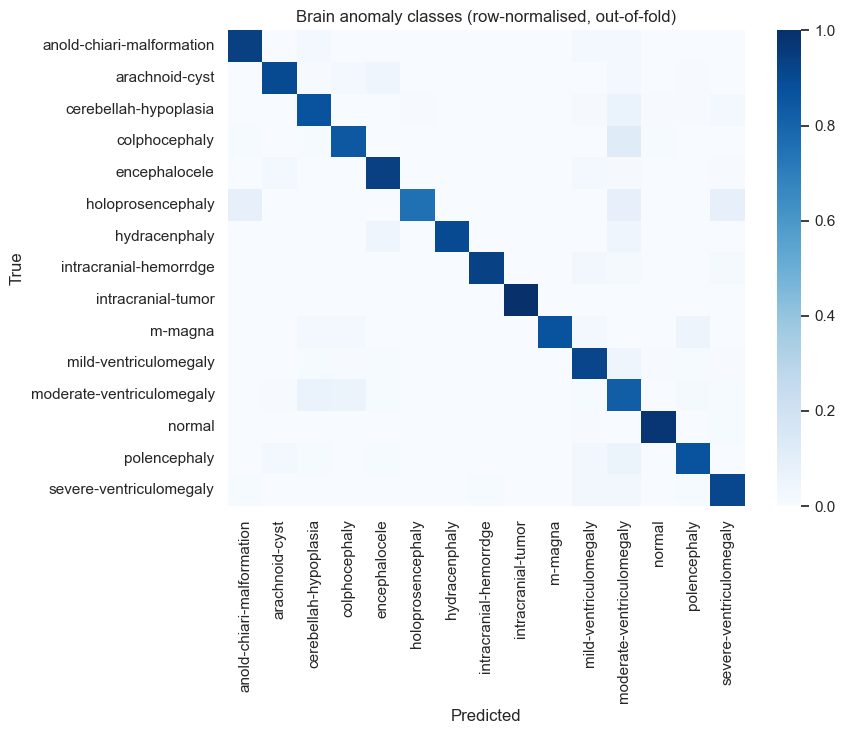

In [20]:
# --- Features, then 5-fold cross-validation grouped by original image ---
if len(anom):
    XA = features(list(anom["path"]), "brainanom")
    A_CLASSES = sorted(anom["cls"].unique())
    ya = anom["cls"].map(A_CLASSES.index).values
    k = min(5, anom.groupby("cls")["group"].nunique().min(), anom["group"].nunique())
    folds_a = np.full(len(anom), -1)
    for i, (_, te) in enumerate(StratifiedGroupKFold(n_splits=max(k, 2), shuffle=True, random_state=SEED)
                                .split(XA, ya, anom["group"])):
        folds_a[te] = i
    P_A = np.zeros((len(anom), len(A_CLASSES)))
    for f in np.unique(folds_a):
        te = folds_a == f
        sc_a, clf_a = fit_logreg(XA[~te], ya[~te])
        P_A[np.ix_(te, clf_a.classes_)] = clf_a.predict_proba(sc_a.transform(XA[te]))
    pred_a = P_A.argmax(1)

    g_idx = list(anom.groupby("group").indices.values())
    def boot_groups(stat):
        rng = np.random.default_rng(SEED); vals = []
        for _ in range(N_BOOT):
            i = np.concatenate([g_idx[j] for j in rng.integers(0, len(g_idx), len(g_idx))])
            try: vals.append(stat(i))
            except ValueError: pass
        return np.nanpercentile(vals, [2.5, 97.5])

    f1_ci = boot_groups(lambda i: f1_score(ya[i], pred_a[i], average="macro"))
    ANOM_RESULT = {"images": len(anom), "classes": len(A_CLASSES), "folds": int(folds_a.max() + 1),
                   "accuracy": (pred_a == ya).mean(), "macro-F1": f1_score(ya, pred_a, average="macro"),
                   "macro-F1 95% CI": f"{f1_ci[0]:.2f}–{f1_ci[1]:.2f}", "chance (largest class)": np.bincount(ya).max() / len(ya)}
    if HAVE_ANOM:
        ni = A_CLASSES.index("normal")
        abn_true, p_abn = (ya != ni).astype(int), 1 - P_A[:, ni]
        flag = (p_abn >= 0.5).astype(int)
        ANOM_RESULT.update({"normal vs abnormal ROC-AUC": roc_auc_score(abn_true, p_abn),
                            "abnormal found (sensitivity)": recall_score(abn_true, flag),
                            "normal kept (specificity)": recall_score(1 - abn_true, 1 - flag)})
    display(pd.DataFrame([ANOM_RESULT]).round(3))
    print(classification_report(ya, pred_a, target_names=A_CLASSES, digits=3, zero_division=0))
    cm = confusion_matrix(ya, pred_a)
    plt.figure(figsize=(max(7, 0.6 * len(A_CLASSES)), max(5, 0.5 * len(A_CLASSES))))
    sns.heatmap(cm / cm.sum(1, keepdims=True).clip(min=1), annot=len(A_CLASSES) <= 10, fmt=".2f", cmap="Blues",
                vmin=0, vmax=1, xticklabels=A_CLASSES, yticklabels=A_CLASSES)
    plt.title("Brain anomaly classes (row-normalised, out-of-fold)"); plt.xlabel("Predicted"); plt.ylabel("True")
    plt.tight_layout(); plt.show()

### 8.1 Safer output: threshold, unfamiliar-image guard and plain-language messages

In [21]:
NICE = {"anold-chiari-malformation": "Arnold-Chiari malformation", "cerebellah-hypoplasia": "cerebellar hypoplasia",
        "colphocephaly": "colpocephaly", "hydracenphaly": "hydranencephaly", "intracranial-hemorrdge": "intracranial haemorrhage",
        "m-magna": "mega cisterna magna", "polencephaly": "porencephaly", "vein-of-galen": "vein of Galen malformation"}
nice = lambda c: NICE.get(c, c.replace("-", " "))          # readable names (fixes spellings in the dataset's class names)

def brain_message(P):
    # P = probabilities over A_CLASSES. Returns a tier and a safe, non-diagnostic message.
    pa = 1 - P[ni]
    top = [A_CLASSES[i] for i in np.argsort(-P) if i != ni][:2]
    alt = f" (or {nice(top[1])})" if len(top) > 1 else ""
    if pa >= TAU_REFER:
        return "refer", pa, f"Possible signs of {nice(top[0])}{alt}. Refer to a specialist for a detailed scan."
    if pa >= TAU_ANOM:
        return "consult", pa, f"Possible brain abnormality (most like {nice(top[0])}). Book the client for a consultation and detailed scan."
    return "no_flag", pa, "The brain check did not flag a concern. This does not rule out a defect; routine anomaly scanning still applies."

if HAVE_ANOM:
    # Flag threshold for >= 90% sensitivity on out-of-fold predictions; "refer" tier at >= 0.8 (or the flag threshold if higher)
    pos = np.sort(p_abn[abn_true == 1])
    TAU_ANOM = float(pos[int(np.floor(0.10 * len(pos)))]) - 1e-9 if len(pos) else 0.5
    TAU_REFER = max(0.8, TAU_ANOM)
    tiers = np.array([brain_message(P_A[i])[0] for i in range(len(anom))])
    flagged = np.isin(tiers, ["refer", "consult"])
    display(pd.DataFrame([{"flag threshold": TAU_ANOM, "refer threshold": TAU_REFER,
                           "abnormal flagged (sensitivity)": flagged[abn_true == 1].mean(),
                           "normal not flagged (specificity)": (~flagged[abn_true == 0]).mean()}]).round(3))
    display(pd.crosstab(pd.Series(np.where(abn_true == 1, "truly abnormal", "truly normal"), name="truth"),
                        pd.Series(tiers, name="output")))

    # Final model + unfamiliar-image guard: an image far from every training image is not assessed
    sc_a, clf_a = fit_logreg(XA, ya)
    def unit(Z):
        Z = sc_a.transform(np.atleast_2d(Z))
        return Z / np.linalg.norm(Z, axis=1, keepdims=True).clip(min=1e-9)
    UA = unit(XA)
    S = UA @ UA.T
    grp = anom["group"].to_numpy(dtype=object)
    S[grp[:, None] == grp[None, :]] = -np.inf                                     # ignore copies of the same original
    OOD_LIMIT = float(np.percentile(1 - S.max(1), 95))                            # 95% of training images are this close to another
    del S

def brain_check(xf):
    # Safe brain check for one image's features: guard first, then tiered message from the final model.
    if not HAVE_ANOM:
        return {"status": "unavailable", "msg": "Brain check unavailable (anomaly dataset not loaded)."}
    if 1 - float((unit(xf) @ UA.T).max()) > OOD_LIMIT:
        return {"status": "not_assessed", "msg": "Brain check could not assess this image: it looks unlike the images the check was trained on."}
    P = np.zeros(len(A_CLASSES)); P[clf_a.classes_] = clf_a.predict_proba(sc_a.transform(np.atleast_2d(xf)))[0]
    status, pa, msg = brain_message(P)
    return {"status": status, "p_abnormal": pa, "msg": msg}

,flag threshold,refer threshold,abnormal flagged (sensitivity),normal not flagged (specificity)
0,0.986,0.986,0.9,1.0


output,no_flag,refer
truth,,
truly abnormal,148,1333
truly normal,282,0


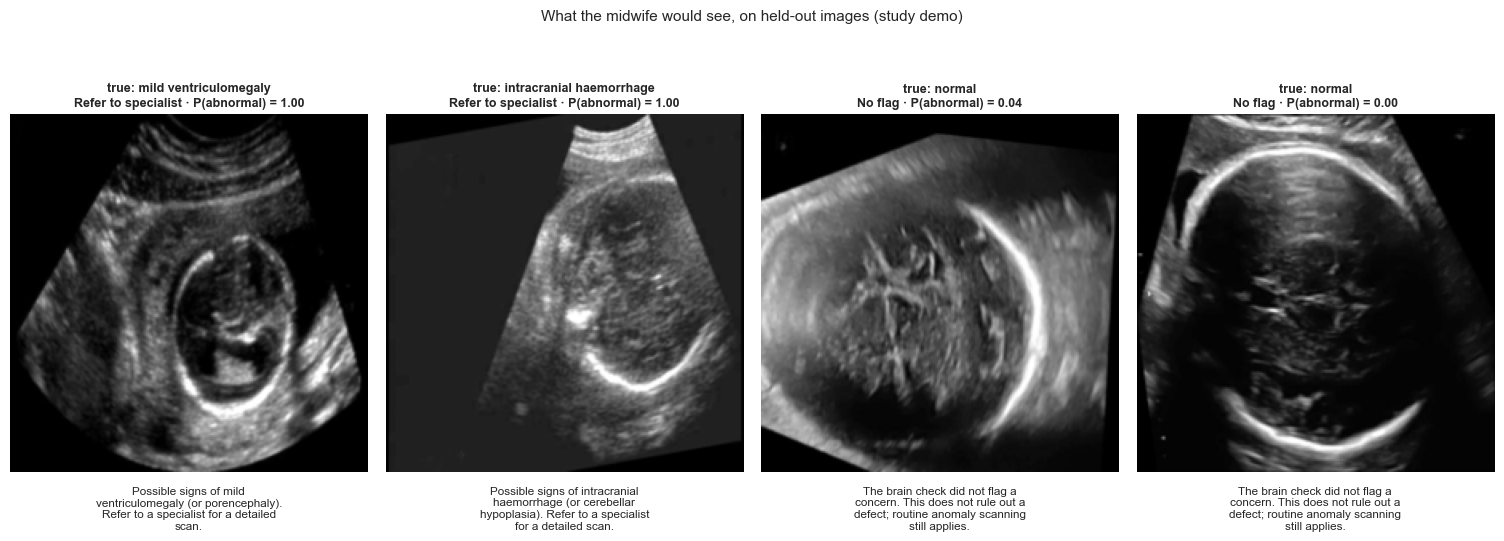

In [22]:
# --- What the midwife would see: example messages on held-out anomaly images (out-of-fold, so never trained on) ---
if HAVE_ANOM:
    show = [i for t in ["refer", "consult", "no_flag"] for i in np.where(tiers == t)[0][:2]]
    import textwrap
    TIER_LABEL = {"refer": "Refer to specialist", "consult": "Book consultation", "no_flag": "No flag"}
    fig, axes = plt.subplots(1, len(show), figsize=(3.8 * len(show), 5.2), squeeze=False)
    for ax, i in zip(axes[0], show):
        tier, pa, msg = brain_message(P_A[i])
        ax.imshow(preprocess_external(Image.open(anom["path"][i]).convert("L")), cmap="gray"); ax.axis("off")
        ax.set_title(f"true: {nice(anom['cls'][i])}\n{TIER_LABEL[tier]} · P(abnormal) = {pa:.2f}", fontsize=9, fontweight="bold")
        ax.text(0.5, -0.04, "\n".join(textwrap.wrap(msg, 36)), transform=ax.transAxes, ha="center", va="top", fontsize=8.5)
    fig.suptitle("What the midwife would see, on held-out images (study demo)", fontsize=11)
    plt.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()

### 8.2 False-alarm check on normal heads from other datasets

In [23]:
# --- False-alarm check: normal heads from our other datasets should be "not assessed" or "no flag" ---
if HAVE_ANOM:
    checks = {"Dummy (NatalIA) head frames": X[Y == 0],
              "Spain trans-thalamic heads (real, normal)": X_SPAIN[Y_SPAIN == 0] if len(X_SPAIN) else X[:0],
              "Africa brain views (real, normal)": X_AFRICA[Y_AFRICA == 0] if len(X_AFRICA) else X[:0]}
    rows_fa = []
    for name, Xh in checks.items():
        st = pd.Series([brain_check(x)["status"] for x in Xh], dtype=object)
        rows_fa.append({"normal heads from": name, "images": len(st),
                        "not assessed (unfamiliar)": (st == "not_assessed").mean() if len(st) else np.nan,
                        "flagged (false alarm)": st.isin(["refer", "consult"]).mean() if len(st) else np.nan,
                        "no flag": (st == "no_flag").mean() if len(st) else np.nan})
    FALSE_ALARMS = pd.DataFrame(rows_fa)
    display(FALSE_ALARMS.round(3))
    print("Ideal: no false alarms. 'Not assessed' is the safe answer for images from other machines; "
          "a high false-alarm share would mean the check learned its own dataset's look, not the anatomy.")

,normal heads from,images,not assessed (unfamiliar),flagged (false alarm),no flag
0,Dummy (NatalIA) head frames,42,1.0,0.0,0.0
1,"Spain trans-thalamic heads (real, normal)",0,NaN,NaN,NaN
2,"Africa brain views (real, normal)",0,NaN,NaN,NaN


Ideal: no false alarms. 'Not assessed' is the safe answer for images from other machines; a high false-alarm share would mean the check learned its own dataset's look, not the anatomy.


### 8.3 Interpretation (write after running)

> **Not run yet.** In the latest run the Roboflow export was not found next to the notebook, so sections 8–8.2 printed nothing. Download the dataset (see section 8), put the zip next to this notebook and rerun from section 8.

*Fill in from the outputs above.* Report: macro-F1 against chance; normal-vs-abnormal AUC, sensitivity and specificity; which classes are confused (the three ventriculomegaly grades are expected to mix); and the false-alarm shares on normal heads from other datasets. A high false-alarm share on real normal heads (Spain, Africa) is an important finding: it would mean a model trained on one unverified dataset does not transfer, which is exactly why a proper, well-documented and ideally Kenyan anomaly dataset is needed.

**How it fits the tool (section 9).** Plane finder (finds the head view in the sweep) → unfamiliar-image guard → brain check on that frame → if flagged, *refer* or *book a consultation*; counselling and decisions are handled by specialists. On the dummy sweeps the guard is expected to say *could not assess*, which is the honest answer for a phantom.

## 9. Midwife visit demo: the care pathway

This section shows how the model would sit inside a midwife's workflow. The order matters:

1. **Danger-sign check first, no AI.** Any danger sign means *urgent referral*, whatever the scan shows. A good scan must never reassure a mother with a danger sign.
2. **Scan quality:** good scan, or please scan again.
3. **Best frames** for each view, ready for remote review.
4. **Referral flags:** possible brain abnormality (section 8: refer or book a consultation; never a diagnosis) and possible breech (section 7), shown **only when a head view was captured**. Otherwise the visit says the position cannot be judged, so a missed head never becomes a false "breech".
5. **Guidance card and referral note.**

**Honesty rules for the demo**
- Every prediction shown comes from the **cross-validation**, so the sweep was never used to train the model that scores it.
- Guidance cards are **placeholders**. Their steps must be taken from Kenya's *National Guidelines for Quality Obstetrics and Perinatal Care* (check the current edition with the Ministry of Health) and WHO antenatal care materials, and **approved by a clinician**. The team does not write treatment steps.
- The danger-sign list follows signs commonly listed in WHO counselling materials; confirm it against the current Kenyan guideline.
- No personal data: each visit gets an anonymous visit ID.

In [24]:
# --- Danger signs and guidance cards (PLACEHOLDER content: to be completed from MOH guidelines, clinician-approved) ---
DANGER_SIGNS = ["Vaginal bleeding", "Convulsions (fits)", "Severe headache or blurred vision", "Fever",
                "Severe abdominal pain", "Fast or difficult breathing", "Reduced or no baby movement"]
CARDS = {
    "urgent":  ("#b3261e", "🚨 Urgent: refer now",
                "A danger sign was reported. Arrange urgent transfer. The scan result does not change this decision.",
                "[First-response steps while arranging transfer: from the MOH guideline, approved by a clinician.]"),
    "rescan":  ("#a15c00", "🔁 Please scan again",
                "No key view was captured. Repeat the sweep, using the vertical pattern (it worked best in our tests).",
                "[How many attempts before escalating, and to whom: from facility protocol.]"),
    "breech":  ("#a15c00", "⚠️ Possible breech: refer for review",
                "The model suggests the baby may be lying bottom-first. A sonographer or clinician should confirm; whether referral is needed depends on how far along the pregnancy is.",
                "[Referral timing and steps for suspected breech: from the MOH guideline, approved by a clinician.]"),
    "defect":  ("#7a3e9d", "🩺 Possible brain abnormality: specialist review",
                "",   # message comes from the brain check (refer, or book a consultation)
                "[Referral pathway for a suspected fetal anomaly: from the MOH guideline or facility protocol, approved by a clinician. "
                "Explain to the client that a more detailed scan is recommended; the specialist discusses any findings.]"),
    "routine": ("#1e6b3a", "✅ Good scan, no flags",
                "Key views were captured and nothing was flagged. Continue routine antenatal care and remind the mother of the danger signs.",
                "[Next-visit schedule and counselling points: from the MOH guideline.]"),
}
VIEW_LABELS = {"biparietal": "head", "abdominal": "tummy", "heart": "heart", "spine": "spine", "femur": "thigh bone"}
P_OOF, PARAMS_OOF = CV[base]["P"], CV[base]["params"]        # out-of-fold predictions of the dummy-trained model

def visit_data(video):
    ix = np.array(sorted(VID_IDX[video], key=lambda i: frames["pos"].values[i]))
    p = PARAMS_OOF[int(frames["fold"].values[ix[0]])]
    P = P_OOF[ix]
    dec = decide(P, p["tau"])
    views = {}
    for c in PLANE_IDS:
        j = int(P[:, c].argmax())
        views[CLASS_NAMES[c]] = {"row": int(frames["row"].values[ix[j]]), "idx": int(ix[j]), "frame": j, "prob": float(P[j, c]),
                                 "found": bool((dec == c).any())}
    return {"video": video, "frames": len(ix), "sweep_type": frames["sweep_type"].values[ix[0]],
            "best": float((1 - P[:, NO_PLANE]).max()), "tau_sweep": p["tau_sweep"],
            "good": bool((1 - P[:, NO_PLANE]).max() >= p["tau_sweep"]), "views": views,
            "p_breech": float(sweep_df["p_breech"].get(video, np.nan)),
            "head_found": views["biparietal"]["found"],
            "brain": brain_check(X[views["biparietal"]["idx"]]) if views["biparietal"]["found"] else None}

In [25]:
# --- One visit, rendered as a report card ---
from datetime import date
from IPython.display import HTML

def midwife_visit(video, danger_signs=(), midwife=""):
    d = visit_data(video)
    # Safety rule: judge position only when a head view was captured (a missing head must never mean "breech")
    breech_flag = d["good"] and d["head_found"] and not np.isnan(d["p_breech"]) and d["p_breech"] >= 0.5
    brain = d["brain"] if d["good"] else None
    defect_flag = brain is not None and brain["status"] in ("refer", "consult")
    key = ("urgent" if danger_signs else "rescan" if not d["good"] else "defect" if defect_flag
           else "breech" if breech_flag else "routine")
    colour, title, action, placeholder = CARDS[key]
    if key == "defect":
        action = brain["msg"]
    brain_txt = ("not assessed (scan not usable)" if not d["good"] else
                 "not assessed (no head view captured)" if brain is None else brain["msg"])
    if key in ("defect", "routine") and breech_flag:
        action += " Also flagged: possible breech (see row 4)."
    visit_id = "V-" + hashlib.md5(video.encode()).hexdigest()[:6].upper()
    found = [VIEW_LABELS[k] for k, v in d["views"].items() if v["found"]]
    signs = ", ".join(danger_signs) if danger_signs else "none reported"
    scan = (f"Good scan (best frame {d['best']:.2f} ≥ {d['tau_sweep']:.2f})" if d["good"]
            else f"Not usable (best frame {d['best']:.2f} < {d['tau_sweep']:.2f})")
    breech_txt = ("not assessed (scan not usable)" if not d["good"] else
                  "cannot judge: no head view captured (repeat the sweep, or clinician review if late in pregnancy)"
                  if not d["head_found"] else
                  f"{'possible breech' if breech_flag else 'head-down likely'} (P(breech) = {d['p_breech']:.2f})")
    row = lambda n, label, value: (f"<tr><td style='padding:4px 10px 4px 0;color:#555;white-space:nowrap'>{n}. {label}</td>"
                                    f"<td style='padding:4px 0'>{value}</td></tr>")
    note = ""
    if key in ("urgent", "breech", "defect"):
        note = (f"<div style='margin-top:10px;padding:10px;border:1px dashed #999;border-radius:6px;font-family:monospace;font-size:12.5px'>"
                f"REFERRAL NOTE · {visit_id} · {date.today().isoformat()}<br>Reason: {title.split(' ', 1)[1]}<br>"
                f"Danger signs: {signs}<br>Scan: {scan}<br>Views captured: {', '.join(found) or 'none'}<br>"
                f"Breech flag: {breech_txt}<br>Brain check (exploratory): {brain_txt}<br>"
                f"Referring midwife: {midwife or '__________'}<br>"
                f"Best frames attached for review.</div>")
    display(HTML(
        f"<div style='max-width:760px;border:1px solid #ccc;border-radius:10px;padding:14px 16px;font-family:sans-serif'>"
        f"<div style='font-size:12px;color:#555'>Visit {visit_id} · {date.today().isoformat()} · {d['sweep_type']} sweep, {d['frames']} frames</div>"
        f"<div style='margin:8px 0;padding:10px 12px;border-radius:8px;background:{colour};color:white;font-weight:600;font-size:16px'>{title}</div>"
        f"<div style='margin-bottom:6px'>{action}</div><div style='font-size:13px;color:#666;margin-bottom:8px'>{placeholder}</div>"
        f"<table style='font-size:14px;border-collapse:collapse'>"
        f"{row(1, 'Danger signs', signs)}{row(2, 'Scan quality', scan)}"
        f"{row(3, 'Views captured', ', '.join(found) if found else 'none')}{row(4, 'Breech flag', breech_txt)}"
        f"{row(5, 'Brain check (exploratory)', brain_txt)}"
        f"{row(6, 'Spine, abdomen, femur checks', 'not available yet (future work: needs labelled data, ideally Kenyan)')}</table>"
        f"{note}<div style='margin-top:10px;font-size:12px;color:#555'>Decision support only. This tool does not diagnose. When in doubt, refer.</div></div>"))
    if d["good"]:                                     # best frame per view, for the sonographer
        fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
        for ax, (k, v) in zip(axes, d["views"].items()):
            ax.imshow(IMAGES[v["row"]], cmap="gray"); ax.axis("off")
            ax.set_title(f"{VIEW_LABELS[k]}: {'✓' if v['found'] else 'not found'}\nframe {v['frame']} · p = {v['prob']:.2f}", fontsize=9)
        fig.suptitle("Best frame per view (for remote review)", fontsize=11)
        plt.tight_layout(); plt.show()

### 9.1 Three example visits

Chosen automatically from the test predictions: a normal visit, a possible breech, and the same breech sweep with a danger sign reported, which shows the danger sign overriding everything.

Normal example: Obstetrics Exam - 02-May-2024_1159_AM | Breech example: Obstetrics Exam - 02-May-2024_1242_PM


1. Danger signs,none reported
2. Scan quality,Good scan (best frame 1.00 ≥ 0.54)
3. Views captured,spine
4. Breech flag,"cannot judge: no head view captured (repeat the sweep, or clinician review if late in pregnancy)"
5. Brain check (exploratory),not assessed (no head view captured)
"6. Spine, abdomen, femur checks","not available yet (future work: needs labelled data, ideally Kenyan)"


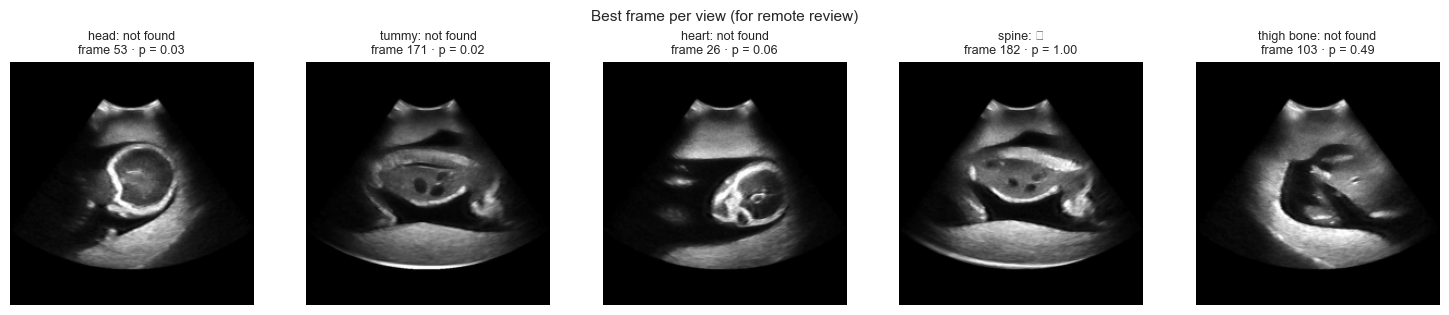

In [26]:
sweep_ok = pd.Series({v: visit_data(v)["good"] for v in sweep_df.index})
pick = lambda mask: (list(sweep_df.index[mask & sweep_ok.reindex(sweep_df.index).values]) or [None])[0]
EX_NORMAL = pick((sweep_df["breech"] == 0).values & (sweep_df["p_breech"] < 0.5).values)
EX_BREECH = (pick((sweep_df["breech"] == 1).values & (sweep_df["p_breech"] >= 0.5).values & sweep_df["head_found"].values)
             or pick((sweep_df["breech"] == 1).values & (sweep_df["p_breech"] >= 0.5).values))
print("Normal example:", EX_NORMAL, "| Breech example:", EX_BREECH)
if EX_NORMAL:
    midwife_visit(EX_NORMAL, midwife="Demo midwife")

1. Danger signs,none reported
2. Scan quality,Good scan (best frame 1.00 ≥ 0.54)
3. Views captured,"head, thigh bone"
4. Breech flag,possible breech (P(breech) = 0.90)
5. Brain check (exploratory),Brain check could not assess this image: it looks unlike the images the check was trained on.
"6. Spine, abdomen, femur checks","not available yet (future work: needs labelled data, ideally Kenyan)"


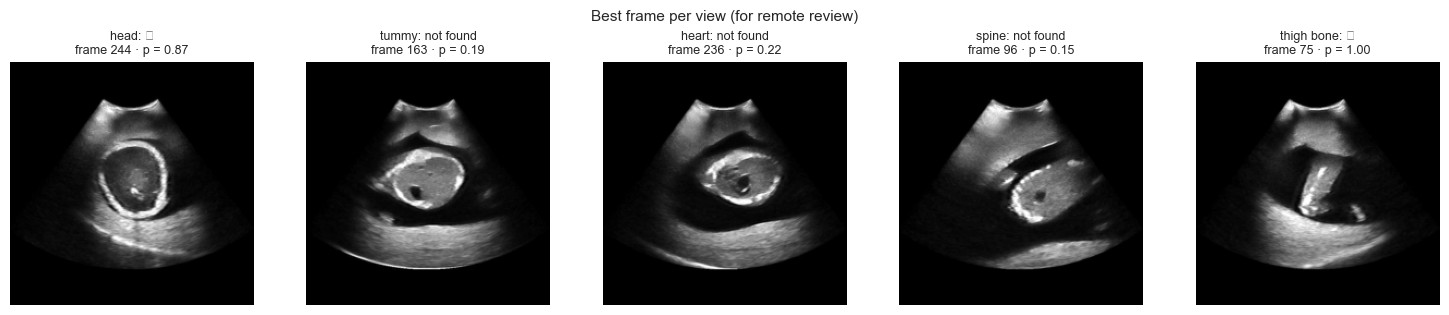

In [27]:
if EX_BREECH:
    midwife_visit(EX_BREECH, midwife="Demo midwife")

1. Danger signs,Vaginal bleeding
2. Scan quality,Good scan (best frame 1.00 ≥ 0.54)
3. Views captured,"head, thigh bone"
4. Breech flag,possible breech (P(breech) = 0.90)
5. Brain check (exploratory),Brain check could not assess this image: it looks unlike the images the check was trained on.
"6. Spine, abdomen, femur checks","not available yet (future work: needs labelled data, ideally Kenyan)"


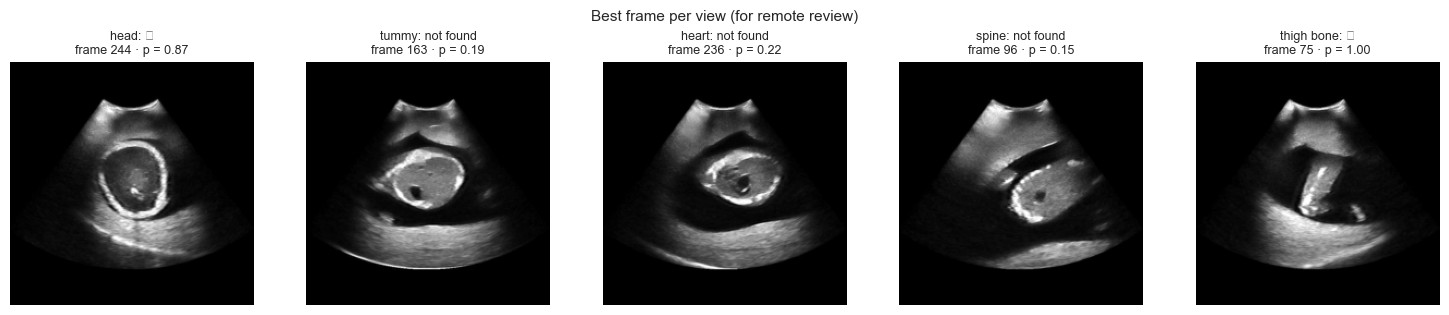

In [28]:
if EX_BREECH:
    midwife_visit(EX_BREECH, danger_signs=["Vaginal bleeding"], midwife="Demo midwife")

### 9.2 Interactive visit (ipywidgets)

Tick any danger signs, choose a sweep and press **Run visit**. Needs `ipywidgets` (`pip install ipywidgets`); in VS Code, widgets work in the Jupyter extension. If widgets are unavailable, the examples above still show every path.

In [29]:
try:
    import ipywidgets as W
    labels = [(f"{k + 1:02d} · {r.sweep_type} · {'breech' if r.breech else 'head-down'} (true)"
               f"{'' if sweep_ok[v] else ' · not usable'}", v)
              for k, (v, r) in enumerate(sweep_df.sort_values(['sweep_type', 'breech']).iterrows())]
    dd = W.Dropdown(options=labels, description="Sweep", layout=W.Layout(width="420px"))
    checks = [W.Checkbox(description=s, value=False, indent=False) for s in DANGER_SIGNS]
    who = W.Text(description="Midwife", placeholder="name (optional)")
    btn = W.Button(description="Run visit", button_style="primary", icon="play")
    out = W.Output()
    def on_run(_):
        with out:
            out.clear_output(wait=True)
            midwife_visit(dd.value, [c.description for c in checks if c.value], who.value)
    btn.on_click(on_run)
    display(W.VBox([W.HTML("<b>1. Danger-sign check (ask the mother first)</b>"),
                    W.GridBox(checks, layout=W.Layout(grid_template_columns="repeat(2, 300px)")),
                    W.HTML("<b>2. Choose the sweep and run the visit</b>"), dd, who, btn, out]))
except ImportError:
    print("ipywidgets is not installed: run `pip install ipywidgets`, restart the kernel, and rerun this cell.")

## 10. Results summary

In [30]:
b, s = RESULTS.iloc[0], RESULTS.iloc[-1]
rows = [
    ("RQ1 Plane macro-F1 (phantom sweeps)", f"{b['plane macro-F1']:.3f} ({b['95% CI']})", "≥ 0.70"),
    ("RQ1 Plane-present AUC / AP (chance)", f"{b['plane-present AUC']:.3f} / {b['plane-present AP']:.3f} ({(Y != NO_PLANE).mean():.3f})", "well above chance"),
    ("RQ2 Sweep hit@5", f"{b['sweep hit@5']:.3f}", "≥ 0.80"),
    ("RQ2 Sweep sensitivity / specificity", f"{b['sweep sensitivity']:.2f} / {b['sweep specificity']:.2f}", "≥ 0.90 / high"),
    ("RQ4 TFLite size / CPU latency", f"{DEPLOY_SUMMARY['TFLite MB']:.1f} MB / {DEPLOY_SUMMARY['CPU ms per frame']:.0f} ms", "< 20 MB / < 200 ms"),
]
if len(RESULTS) > 1:
    rows.append(("RQ5a Plane macro-F1 with Spanish images", f"{s['plane macro-F1']:.3f} ({s['95% CI']})", "higher than without"))
if len(africa):
    for _, r in AFRICA_RESULTS.iterrows():
        rows.append((f"RQ5b African scans, {r['model']}: detected / right view",
                     f"{r['detected as key view']:.2f} / {r['right view (accuracy)']:.2f}", "as high as possible"))
if "BREECH" in globals():
    rows.append(("RQ6 Breech flag: accuracy (95% CI) / AUC", f"{BREECH['accuracy']:.2f} ({BREECH['accuracy 95% CI']}) / {BREECH['ROC-AUC']:.2f}",
                 f"above chance ({BREECH['chance (majority class)']:.2f})"))
    if "best no-head rule AUC" in BREECH:
        rows.append(("RQ6 Shortcut check: best 'no head' rule AUC", f"{BREECH['best no-head rule AUC']:.2f}",
                     f"clearly below the model's {BREECH['ROC-AUC']:.2f}"))
if "ANOM_RESULT" in globals() and "TAU_ANOM" in globals():
    rows.append(("Defect screening (exploratory): normal vs abnormal AUC / flagged sensitivity / specificity",
                 f"{ANOM_RESULT['normal vs abnormal ROC-AUC']:.2f} / {flagged[abn_true == 1].mean():.2f} / {(~flagged[abn_true == 0]).mean():.2f}",
                 "sensitivity ≥ 0.90 (screening)"))
SUMMARY = pd.DataFrame(rows, columns=["question", "result", "target"])
display(SUMMARY)
SUMMARY.to_csv(OUT_DIR / "headline_results.csv", index=False)
RESULTS.to_csv(OUT_DIR / "phantom_results.csv", index=False)

,question,result,target
0,RQ1 Plane macro-F1 (phantom sweeps),0.379 (0.303–0.434),≥ 0.70
1,RQ1 Plane-present AUC / AP (chance),0.915 / 0.339 (0.018),well above chance
2,RQ2 Sweep hit@5,0.760,≥ 0.80
3,RQ2 Sweep sensitivity / specificity,0.85 / 0.31,≥ 0.90 / high
4,RQ4 TFLite size / CPU latency,7.2 MB / 339 ms,< 20 MB / < 200 ms
5,RQ6 Breech flag: accuracy (95% CI) / AUC,0.78 (0.69–0.87) / 0.86,above chance (0.54)
6,RQ6 Shortcut check: best 'no head' rule AUC,0.61,clearly below the model's 0.86
7,Defect screening (exploratory): normal vs abno...,1.00 / 0.90 / 1.00,sensitivity ≥ 0.90 (screening)


## 11. Conclusions

*Figures from this run (section 10). "Spain" = 400 real Spanish images per view added to training.*

- **RQ1: finding planes.** The model detects that *a* plane is present far above chance (ROC-AUC 0.921; AP 0.352 against 0.018 chance), but plane macro-F1 is 0.388 (95% CI 0.316–0.444), well below the 0.70 target. Head (F1 0.59) and heart (0.58) are found best, abdomen (0.39) and spine (0.35) partly, and the femur hardly at all (0.04).
- **RQ2: the sweep decision.** A correct frame is in the top 5 for 77% of plane–sweep pairs, which supports a "show the best frames" workflow. The rescan decision passes 83% of sweeps that hold a plane but flags only 47% of empty ones (target 0.90 / high), so it is not yet reliable enough for unsupervised use.
- **RQ3: robustness.** Sweep type matters a lot: plane recall is 0.72 for vertical sweeps but 0.27–0.39 for diagonal and horizontal ones, and sweep sensitivity falls from 0.95 (vertical) to 0.63 (diagonal 1). A single, standardised sweep protocol would help directly.
- **RQ4: deployment.** The packaged model is 7.1 MB, scores a frame in 178 ms on a laptop CPU (target < 200 ms) and agrees with the full model on 98.4% of frames. Phone performance still needs testing.
- **RQ5a: real images on the phantom.** Adding Spanish images gives a small, uncertain gain on the dummy sweeps (macro-F1 0.388 → 0.404, intervals overlap; femur 0.04 → 0.10, head 0.59 → 0.62) and slightly weaker sweep decisions (sensitivity 0.83 → 0.80, specificity 0.47 → 0.44).
- **RQ5b: real African scans.** This is the clearest result. Trained on the dummy alone, the model recognises 0.2% of 450 African scans as key views and names the right view 21% of the time (no better than guessing among four). With Spanish images it recognises 75% and names the right view **80%** of the time (macro-F1 0.75, 95% CI 0.70–0.79), from 72% (Algeria) to 92% (Uganda). Ghana and Uganda have no heart images, so country differences are partly a mix effect. **Phantom data alone is not enough; real, ideally Kenyan, data is essential.**
- **RQ6: breech flag (feasibility).** From the sweep alone, the flag tells head-down from breech with accuracy 0.82 (95% CI 0.74–0.90) against 0.54 by always guessing the commonest position, and ROC-AUC 0.86 (0.78–0.94). It found 31 of 41 breech sweeps (sensitivity 0.76) and was right for 43 of 49 head-down sweeps (specificity 0.88); diagonal 1 sweeps were weakest (0.70). **Shortcut check:** simple "no head seen" rules reach at most 0.62, and in the opposite direction to the worry (a head view was found more often in breech sweeps: 12 of the 15 sweeps where one was found), so the flag is not just reading "no head". This is one phantom in four positions at 23 weeks: it shows technical feasibility, not clinical accuracy.
- **Defect screening (section 8, exploratory).** Not run in this execution because the Roboflow dataset was not downloaded. Once run, report it from section 8.3; the dataset is unverified, so any result shows what a proper anomaly dataset could enable, not clinical performance.
- **Care pathway (section 9).** The three example visits ran: danger signs first, then scan quality, best frames, the breech flag (shown only when a head view was captured), a guidance card and a referral note. Guidance content is a placeholder until taken from Kenyan MOH guidelines and approved by a clinician. The interactive version (9.2) needs `pip install ipywidgets`.

**Responsible use.** Decision support only: the tool never diagnoses or decides treatment; danger signs always override the scan; a named clinician makes every decision; real use needs clinical validation in Kenya, Pharmacy and Poisons Board approval, consent and data protection.

**Limitations.** Phantom sweeps from one probe and one gestational age; few positive frames (345), so intervals are wide; real-image tests use expert-chosen still images, none from Kenya; frozen ImageNet backbone; settings fixed from exploratory runs on the same phantom data; not a diagnostic tool and not clinically validated.

**Future work: defect checks for other views.** The plane finder already locates the abdomen, heart, spine and femur views, so each could get its own check with the same safe messages and unfamiliar-image guard: **spine** (e.g. spina bifida), **abdomen** (e.g. gastroschisis, omphalocele) and **femur** (e.g. short limbs suggesting skeletal dysplasia, which also needs the pregnancy age). We found no suitable public labelled datasets for these, so they need **labelled ultrasound data, ideally from Kenya**, collected with consent and ethics approval and labelled by specialists. A heart check could use the [Heartbeat](https://github.com/BCV-Uniandes/Heartbeat) dataset (access by academic request).

**Next steps.** Add a few African patients per country to training; fine-tune the backbone on a GPU at higher resolution; test on real novice sweeps (ACOUSLIC-AI, Sierra Leone); seek Kenyan data (AIMIX) for local validation.

**Data citations.** González et al. (2024), NatalIA PBF-US1, [doi:10.5281/zenodo.14193949](https://doi.org/10.5281/zenodo.14193949); Burgos-Artizzu et al. (2020), FETAL_PLANES_DB, [zenodo.org/record/3904280](https://zenodo.org/record/3904280); Sendra-Balcells et al. (2023), African fetal planes, [zenodo.org/records/7540448](https://zenodo.org/records/7540448).